<a href="https://colab.research.google.com/github/jhondev123/AZ-104-MicrosoftAzureAdministrator/blob/master/33_Regressao_Logistica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regressão Logística

Apesar do nome "Regressão", este algoritmo é utilizado para problemas de **Classificação**. Enquanto na Regressão Linear prevíamos valores contínuos (como o preço de uma casa), na Regressão Logística prevemos a probabilidade de um registro pertencer a uma **classe** (Ex: "Sim" ou "Não", "Benigno" ou "Maligno").

O algoritmo utiliza a **função sigmóide** para mapear qualquer valor real em um intervalo entre 0 e 1, que interpretamos como a probabilidade de ocorrência de um evento.

<img src="https://upload.wikimedia.org/wikipedia/commons/8/88/Logistic-curve.svg" width="300">

Figura: Função Sigmóide - Fonte: [Wikipedia](https://pt.wikipedia.org/wiki/Fun%C3%A7%C3%A3o_sigm%C3%B3ide)



## Bibliotecas

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.datasets import load_breast_cancer

%matplotlib inline

## 1. Objetivo da Aula
Utilizaremos o dataset [Breast Cancer Wisconsin](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html). O objetivo é classificar tumores como **Malignos** ou **Benignos** com base em características clínicas (raio, textura, perímetro, etc.).

### Carregamento e Exploração

In [ ]:
# Carregando o dataset
data = load_breast_cancer()

# Criando o DataFrame
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target

# Visualizando as classes (0 = Maligno, 1 = Benigno)
print(f"Classes: {data.target_names}")
df.head()

Classes: ['malignant' 'benign']


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [ ]:
print(df.columns)

Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension',
       'target'],
      dtype='object')


## 2. Regressão Logística Simples
Para facilitar a visualização, vamos tentar prever o diagnóstico usando apenas uma variável: **mean radius** (raio médio). Note que, ao contrário da linear, aqui os pontos no gráfico estão concentrados em 0 ou 1 no eixo Y.

In [ ]:
# Selecionando apenas uma característica
X_simple = df[['mean radius']]
y_simple = df['target']

print(type(X_simple))
print(type(y_simple))

<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.series.Series'>


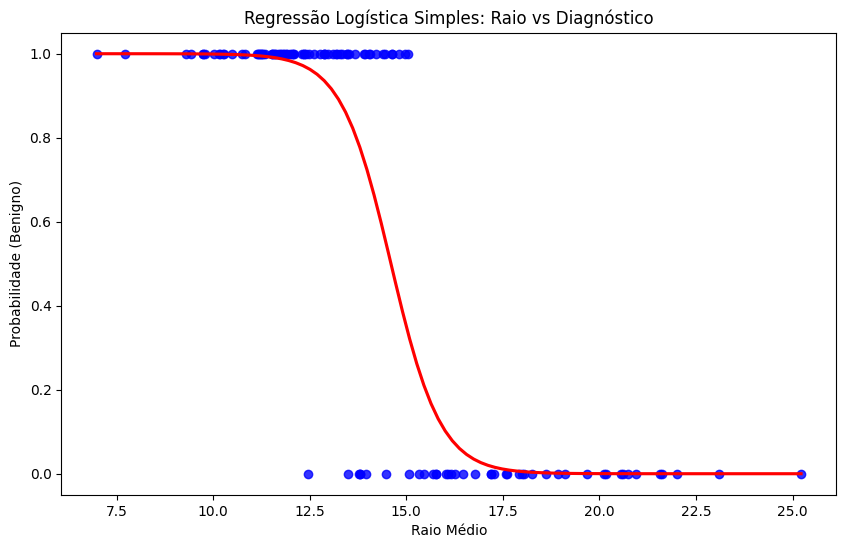

In [ ]:
# Selecionando apenas uma característica
X_simple = df[['mean radius']]
y_simple = df['target']

# Divisão Treino/Teste
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_simple, y_simple, test_size=0.2, random_state=42)

# Treinamento
model_simple = LogisticRegression()
model_simple.fit(X_train_s, y_train_s)

# Visualização da Curva Logística
plt.figure(figsize=(10, 6))
sns.regplot(x=X_test_s, y=y_test_s, logistic=True, ci=None, scatter_kws={'color': 'blue'}, line_kws={'color': 'red'})
plt.xlabel('Raio Médio')
plt.ylabel('Probabilidade (Benigno)')
plt.title('Regressão Logística Simples: Raio vs Diagnóstico')
plt.show()

## 3. Regressão Logística Múltipla
Agora, utilizaremos todas as 30 características disponíveis para tornar nosso classificador mais robusto.

In [ ]:
# Preparação dos dados completos
X_multi = df.drop('target', axis=1)
y_multi = df['target']

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_multi, y_multi, test_size=0.2, random_state=42)

# Treinamento
model_multi = LogisticRegression(max_iter=10000)
model_multi.fit(X_train_m, y_train_m)

# Previsões
y_pred_m = model_multi.predict(X_test_m)

## 4. Avaliação de Classificação
Diferente da Regressão Linear (onde usamos MAE/R²), na classificação usamos métricas baseadas em acertos e erros categóricos.

* **Acurácia:** Porcentagem total de acertos.
* **Matriz de Confusão:** Tabela que mostra Falsos Positivos e Falsos Negativos.
* **Precision/Recall:** Indicam a qualidade do modelo em identificar cada classe especificamente.

--- Avaliação do Modelo Múltiplo ---
Acurácia: 0.9561

Matriz de Confusão:


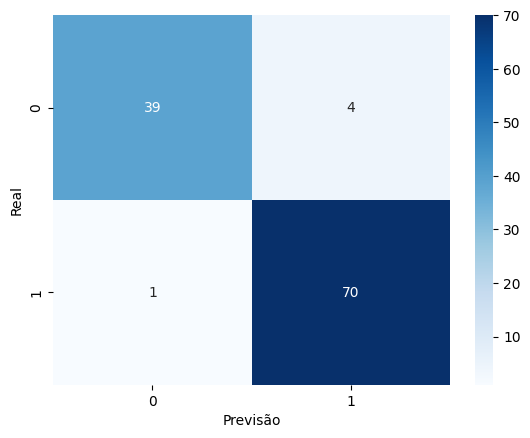


Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.97      0.91      0.94        43
           1       0.95      0.99      0.97        71

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [ ]:
# Resultados
print("--- Avaliação do Modelo Múltiplo ---")
print(f"Acurácia: {accuracy_score(y_test_m, y_pred_m):.4f}")
print("\nMatriz de Confusão:")
conf_matrix = confusion_matrix(y_test_m, y_pred_m)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Previsão')
plt.ylabel('Real')
plt.show()

print("\nRelatório de Classificação:")
print(classification_report(y_test_m, y_pred_m))

### 4.2. Interpretando os Resultados da Classificação

Ao analisar a saída do modelo para o dataset de Câncer de Mama, temos dois componentes principais:

#### 1. Matriz de Confusão (Heatmap)
A matriz nos mostra onde o modelo acertou e onde ele foi "confundido":
* **Eixo Y (Real):** O diagnóstico verdadeiro do paciente.
* **Eixo X (Previsão):** O que o modelo disse que era.
* **Diagonal Principal (Canto superior esquerdo e inferior direito):** Representa os acertos (Verdadeiros Negativos e Verdadeiros Positivos).
* **Fora da diagonal:** Representa os erros. Em contextos médicos, um **Falso Negativo** (prever que é benigno quando é maligno) é o erro mais crítico.

#### 2. Métricas do Classification Report
* **Precision (Precisão):** De todos os que o modelo classificou como uma classe, quantos ele realmente acertou? É sobre a "qualidade" da previsão.
* **Recall (Revocação):** De todos os casos reais de uma classe que existiam, quantos o modelo conseguiu encontrar? É sobre a "capacidade de busca".
* **F1-Score:** É uma média harmônica entre Precision e Recall. É a métrica ideal quando queremos um equilíbrio entre não dar alarmes falsos e não deixar passar casos reais.
* **Accuracy (Acurácia):** É o desempenho geral do modelo (total de acertos / total de casos). No seu resultado, uma acurácia de **0.95 (95%)** indica um modelo extremamente sólido.



> **Dica:** Na saúde, é melhor ter um falso alarme (baixa precisão) do que deixar um tumor maligno passar despercebido (baixo recall).